# EJERCICIO 3: Programación de turnos de producción

Enunciado
En una planta con 4 líneas de producción, se deben asignar turnos diarios para cubrir 3 tipos de productos con diferente urgencia y rentabilidad.

El objetivo es maximizar la rentabilidad ponderada por urgencia, evitando sobrecarga de líneas y cumpliendo con los límites de horas laborales.

Variables
* Genotipo: matriz (líneas × productos)
* Fitness: rentabilidad total ajustada por urgencia
* Restricciones: total de horas por línea ≤ 8

Escenarios
* Cruce 2 puntos vs uniforme
* Mutación aleatoria vs dirigida por urgencia
* Análisis de convergencia vs diversidad poblacional

In [1]:
%pip install deap

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Solución utilizando librería DEAP
import random
import numpy as np
from deap import base, creator, tools, algorithms
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [3]:
# Parámetros del problema
NUM_LINES = 4
NUM_PRODUCTS = 3
MAX_HOURS = 8

In [4]:
# Rentabilidad por producto y urgencia (ficticios)
rentabilidad = np.array([100, 150, 200])
urgencia = np.array([1.0, 1.5, 2.0])  # Ponderadores

def generar_individuo():
    # Asigna productos (0, 1, 2) a cada línea de producción
    return [random.randint(0, NUM_PRODUCTS-1) for _ in range(NUM_LINES)]

def evaluar_turno(ind):
    horas_por_linea = np.random.randint(6, 9, size=NUM_LINES)  # horas ficticias
    if np.any(horas_por_linea > MAX_HOURS):
        return 0.0,
    beneficio = 0
    for i, prod in enumerate(ind):
        beneficio += rentabilidad[prod] * urgencia[prod]
    return beneficio,

In [5]:
# Configuración DEAP
creator.create("FitnessMaxTurno", base.Fitness, weights=(1.0,))
creator.create("IndividuoTurno", list, fitness=creator.FitnessMaxTurno)

toolbox = base.Toolbox()
toolbox.register("attr_prod", random.randint, 0, NUM_PRODUCTS-1)
toolbox.register("individual", tools.initRepeat, creator.IndividuoTurno, toolbox.attr_prod, n=NUM_LINES)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

toolbox.register("evaluate", evaluar_turno)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutUniformInt, low=0, up=NUM_PRODUCTS-1, indpb=0.3)
toolbox.register("select", tools.selRoulette)

In [6]:
# Ejecutar algoritmo
pop = toolbox.population(n=30)
hof = tools.HallOfFame(1)
stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("avg", np.mean)
stats.register("max", np.max)
stats.register("min", np.min)

pop, log = algorithms.eaSimple(pop, toolbox, cxpb=0.8, mutpb=0.3, ngen=40,
                                stats=stats, halloffame=hof, verbose=False)

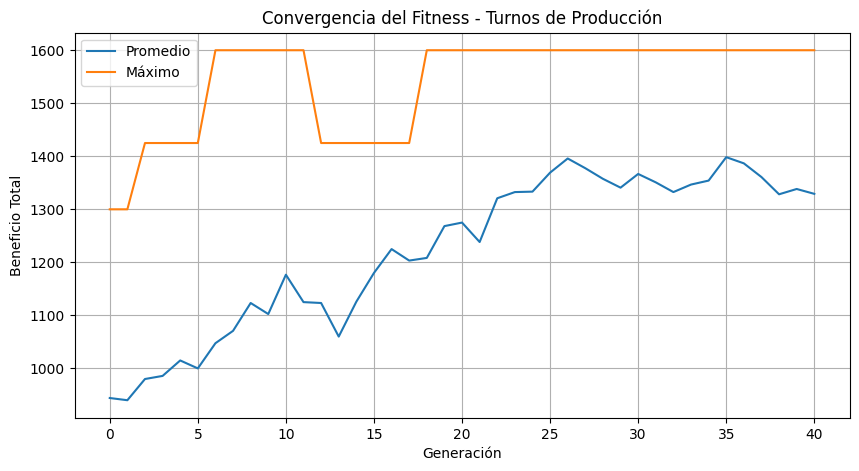

In [7]:
# Visualización de convergencia
log_df = pd.DataFrame(log)
plt.figure(figsize=(10, 5))
plt.plot(log_df['gen'], log_df['avg'], label='Promedio')
plt.plot(log_df['gen'], log_df['max'], label='Máximo')
plt.xlabel("Generación")
plt.ylabel("Beneficio Total")
plt.title("Convergencia del Fitness - Turnos de Producción")
plt.legend()
plt.grid(True)
plt.show()

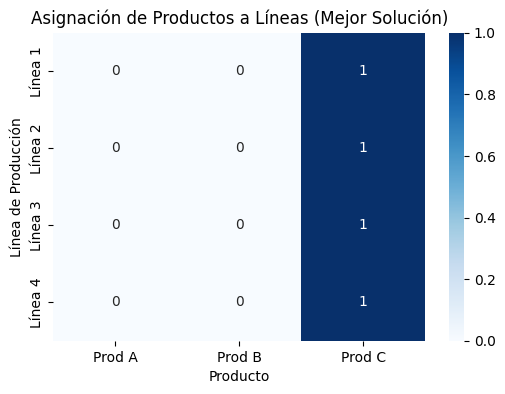

In [8]:
# Visualización matriz de calor de asignación
mejor = hof[0]
asignacion = np.zeros((NUM_LINES, NUM_PRODUCTS))
for i, prod in enumerate(mejor):
    asignacion[i][prod] = 1

plt.figure(figsize=(6, 4))
sns.heatmap(asignacion, annot=True, cmap="Blues", xticklabels=["Prod A", "Prod B", "Prod C"],
            yticklabels=[f"Línea {i+1}" for i in range(NUM_LINES)])
plt.title("Asignación de Productos a Líneas (Mejor Solución)")
plt.xlabel("Producto")
plt.ylabel("Línea de Producción")
plt.show()